In [2]:
import warnings
warnings.filterwarnings("ignore", category=Warning)
warnings.simplefilter(action='ignore', category=FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
!pip install tensorflow
import tensorflow_datasets as tfds
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


[notice] A new release of pip is available: 25.2 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
dftrain = pd.read_csv("data/train.csv")
dftrain.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
dftest = pd.read_csv("data/test.csv")
dftest.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
#Split data 
X = dftrain.drop("label", axis=1).values
y = dftrain["label"].values
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [6]:
#Reshape 
X_train = X_train.reshape(-1, 28, 28, 1)
X_val = X_val.reshape(-1, 28, 28, 1)

In [7]:
#Normalize 
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0

In [8]:
#Build CNN
num_conv1 = 32 
num_conv2 = 64 
num_hidden3 = 128  
num_output = 10
k_size = 3
p_size = 2


model = Sequential([
    Conv2D(num_conv1, kernel_size=(k_size, k_size),activation='relu', input_shape=(28, 28, 1)),

    MaxPooling2D(pool_size=(p_size, p_size)),

    Conv2D(num_conv2, kernel_size=(k_size, k_size), activation='relu'),
    MaxPooling2D(pool_size=(p_size, p_size)),

    Flatten(),

    Dense(num_hidden3, activation='relu'),
    Dense(num_output, activation='softmax') 
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [10]:
num_epochs = 10
history = model.fit(X_train, y_train, epochs=num_epochs, validation_split=0.2)

Epoch 1/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9374 - loss: 0.2039 - val_accuracy: 0.9641 - val_loss: 0.1031
Epoch 2/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9808 - loss: 0.0608 - val_accuracy: 0.9804 - val_loss: 0.0647
Epoch 3/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9866 - loss: 0.0407 - val_accuracy: 0.9836 - val_loss: 0.0636
Epoch 4/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9903 - loss: 0.0288 - val_accuracy: 0.9854 - val_loss: 0.0558
Epoch 5/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.9931 - loss: 0.0200 - val_accuracy: 0.9853 - val_loss: 0.0593
Epoch 6/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.9946 - loss: 0.0155 - val_accuracy: 0.9876 - val_loss: 0.0538
Epoch 7/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.9959 - loss: 0.0123 - val_accuracy: 0.9832 - val_loss: 0.0708
Epoch 8/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.9965 - loss: 0.0111 - 

In [11]:
#Evaluation
test_loss, test_accuracy = model.evaluate(X_val, y_val)
print(f"Validation accuracy: {test_accuracy}")

263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9885 - loss: 0.0446
Validation accuracy: 0.9884523749351501


In [13]:
#Fine Tune Model
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
model = Sequential([
    Conv2D(num_conv1, kernel_size=(k_size, k_size),activation='relu', input_shape=(28, 28, 1)),

    MaxPooling2D(pool_size=(p_size, p_size)),

    Conv2D(num_conv2, kernel_size=(k_size, k_size), activation='relu'),
    MaxPooling2D(pool_size=(p_size, p_size)),

    Flatten(),

    Dense(num_hidden3, activation='relu'),
    Dropout(0.5),
    Dense(num_output, activation='softmax') 
    
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stop = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

In [16]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [17]:
history = model.fit(X_train, y_train,epochs=20,validation_data=(X_val, y_val),callbacks=[early_stop])

Epoch 1/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.9163 - loss: 0.2717 - val_accuracy: 0.9795 - val_loss: 0.0662
Epoch 2/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.9732 - loss: 0.0919 - val_accuracy: 0.9845 - val_loss: 0.0490
Epoch 3/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.9794 - loss: 0.0681 - val_accuracy: 0.9890 - val_loss: 0.0366
Epoch 4/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.9840 - loss: 0.0549 - val_accuracy: 0.9871 - val_loss: 0.0396
Epoch 5/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.9858 - loss: 0.0466 - val_accuracy: 0.9893 - val_loss: 0.0360
Epoch 6/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.9886 - loss: 0.0394 - val_accuracy: 0.9911 - val_loss: 0.0314
Epoch 7/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.9893 - loss: 0.0328 - val_accuracy: 0.9889 - val_loss: 0.0383
Epoch 8/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9900 -

In [18]:
#Re-evaluation
test_loss, test_accuracy = model.evaluate(X_val, y_val)
print(f"Validation accuracy: {test_accuracy}")

263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9915 - loss: 0.0303
Validation accuracy: 0.9915476441383362


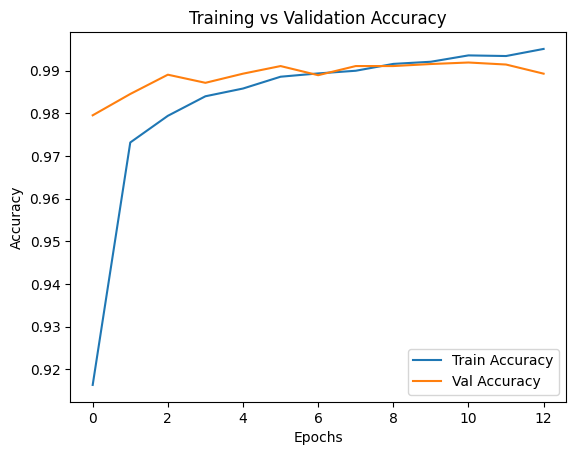

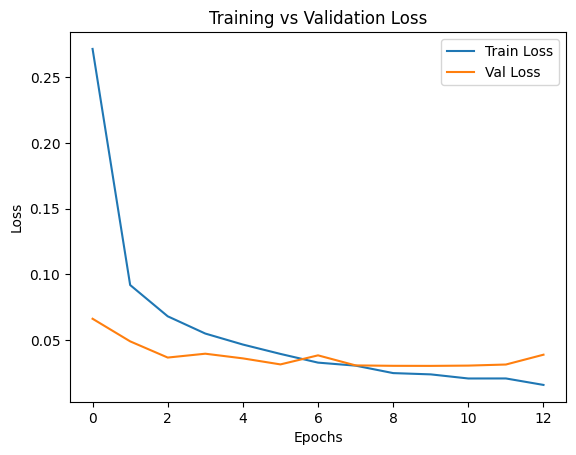

In [19]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()

In [20]:
#Additional analyses of your results
y_pred = model.predict(X_val)
y_pred_classes = y_pred.argmax(axis=1)

correct = np.where(y_pred_classes == y_val)[0]
incorrect = np.where(y_pred_classes != y_val)[0]

263/263 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step


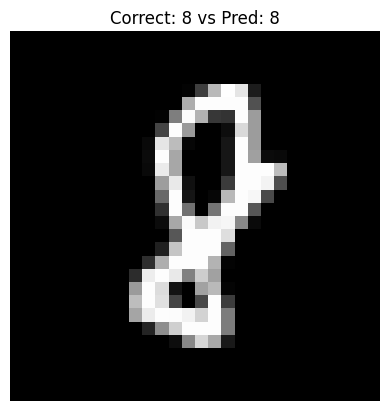

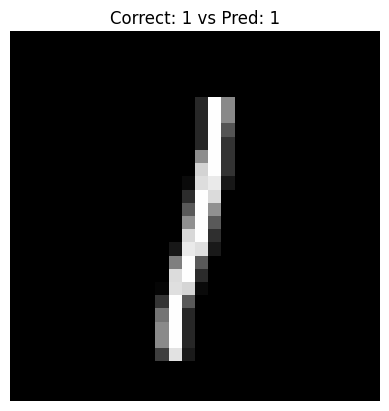

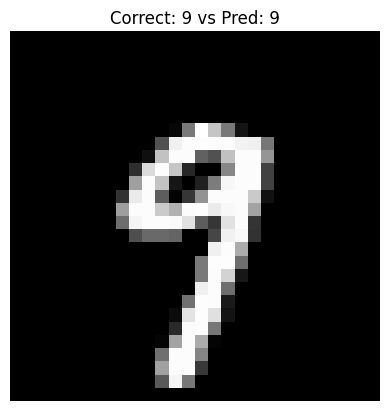

In [23]:
for i in correct[:3]:
    plt.imshow(X_val[i].reshape(28,28), cmap='gray')
    plt.title(f"Correct: {y_val[i]} vs Pred: {y_pred_classes[i]}")
    plt.axis('off')
    plt.show()

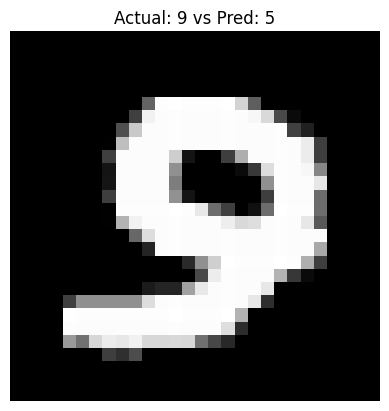

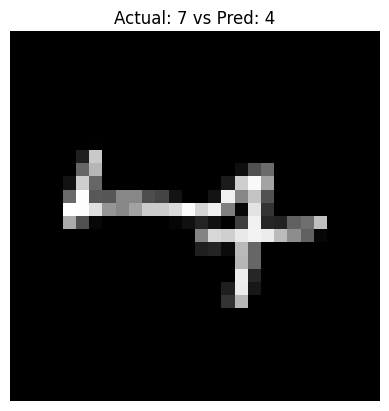

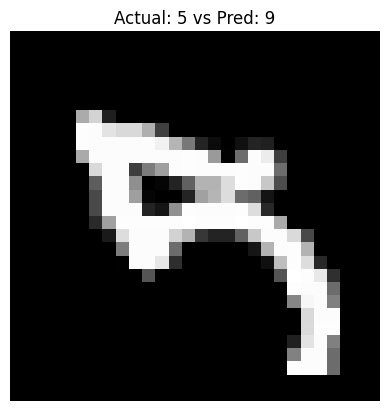

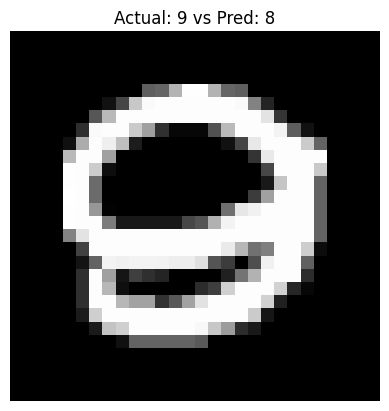

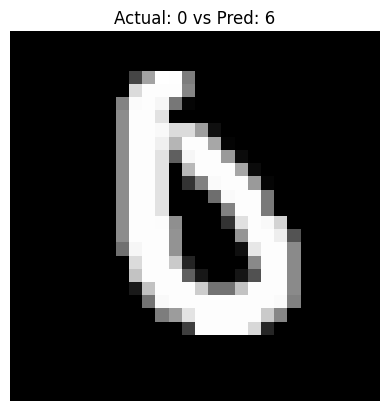

In [24]:
for i in incorrect[:5]:
    plt.imshow(X_val[i].reshape(28,28), cmap='gray')
    plt.title(f"Actual: {y_val[i]} vs Pred: {y_pred_classes[i]}")
    plt.axis('off')
    plt.show()